(pseudobulk_and_differential_expression)=

# Pseudobulk and differential expression (DE) primer

To compare gene expression changes across conditions, we need independent biological samples in each group. Pseudobulking works for single-cell RNA sequencing data because summing raw counts within each donor produces donor-level count data that mirrors bulk RNA-seq count data. Testing for differential expression tells us which genes change between conditions, pointing to the programs driving disease or response. Without it, we can describe what genes are present and potentially driving an effect, but not what is different about them across the conditions.

## Dataset and study design

The data come from the CZ CELLxGENE collection [Single-cell RNA-Seq analysis reveals cell subsets and gene signatures associated with rheumatoid arthritis disease activity](https://cellxgene.cziscience.com/collections/e1a9ca56-f2ee-435d-980a-4f49ab7a952b), published with [Binvignat et al.](https://doi.org/10.1172/jci.insight.178499). The study contains PBMCs from 18 people with rheumatoid arthritis (RA) and 18 matched controls processed across three batches. If you remember correctly, this is the same dataset used in the [](condition_comparisons.ipynb)

Here each sample is a donor. This tutorial simply goes through the motions of preparing our data for true DE analysis, by summing the raw counts from γδ T cells into one column per donor, keeping the matched study design, and thus exporting the result for a method such as edgeR or DESeq2. CyteArc performs the aggregation and export. It does not fit the differential expression model on this page.

## Prepare the study data

To begin, simply download the dataset and inspect it to derive the existing information.

In [1]:
# Read the optional local data-directory setting.
from os import environ

# Manage local file and directory paths.
from pathlib import Path

# Create temporary directories for this example.
from tempfile import TemporaryDirectory

# Download the published input file.
from urllib.request import urlretrieve

# Arrange and save Matplotlib figures.
import matplotlib.pyplot as plt

# Work with numeric arrays and cell masks.
import numpy as np

# Summarize cells and results in tables.
import pandas as pd

# Open count stores and run CyteArc analyses.
import cytearc

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Use the pinned public H5AD download.
dataset_url = (
    "https://datasets.cellxgene.cziscience.com/"
    "3b751975-34bb-409a-a9b7-98380f0450ea.h5ad"
)

# Choose the local directory for reusable input data.
dataset_directory = Path(environ.get("CYTEARC_DOCS_DATA_DIR", "cytearc_datasets"))

# Create the output directory if needed.
dataset_directory.mkdir(parents=True, exist_ok=True)

# Locate the H5AD file to inspect.
h5ad_path = dataset_directory / "binvignat_ra_pbmc.h5ad"

# Show the input filename used by this step.
h5ad_path.name

'binvignat_ra_pbmc.h5ad'

Started: 2026-10-23T14:34:30.153054Z | Wall time: 1.437 s

Download the file if it is not already present.

In [2]:
# Reuse the existing local input when it is already available.
if not h5ad_path.exists():

    # Download to a temporary filename until the file is complete.
    partial_path = h5ad_path.with_suffix(".h5ad.part")

    # Download the published H5AD file.
    urlretrieve(dataset_url, partial_path)

    # Move the completed input into its reusable local path.
    partial_path.replace(h5ad_path)

# Confirm the written filename and its size in bytes.
{"file": h5ad_path.name, "bytes": h5ad_path.stat().st_size}

{'file': 'binvignat_ra_pbmc.h5ad', 'bytes': 259685464}

Started: 2026-10-23T14:34:31.593204Z | Wall time: 1.291 s

Inspect the available matrices before converting the file.

In [3]:
# Inspect the available count matrices and metadata.
inspection = cytearc.inspect_h5ad(str(h5ad_path))

# Require the raw count matrix for pseudobulk.
assert inspection.matrixKey == "raw/X"

# Require integer-like counts for downstream count models.
assert inspection.integerLike is True

# Check the dimensions of the pinned source file.
assert (inspection.nCells, inspection.nFeatures) == (108_717, 21_648)

# Inspect the selected count matrix, encoding, and dimensions.
{
    "matrix": inspection.matrixKey,
    "encoding": inspection.matrixEncoding,
    "integer-like": inspection.integerLike,
    "shape": (inspection.nCells, inspection.nFeatures),
}

{'matrix': 'raw/X',
 'encoding': 'csr',
 'integer-like': True,
 'shape': (108717, 21648)}

Started: 2026-10-23T14:34:32.887396Z | Wall time: 0.686 s

After inspection, we see the expected 108,717 cells by 21,648 features (genes). We can then proceed by converting the .h5ad file to its corresponding zarr format.

In [4]:
# Choose the reusable converted count store.
source_store = dataset_directory / "binvignat_ra_pbmc.zarr"

# Reuse the existing local input when it is already available.
if not source_store.exists():

    # Keep an incomplete conversion separate from the reusable source.
    with TemporaryDirectory(dir=dataset_directory) as conversion_directory:

        # Write the conversion to a temporary store before publishing it locally.
        staged_store = Path(conversion_directory) / source_store.name

        # Open a reader for the selected source format.
        reader = cytearc.H5adReader.from_inspect(inspection)

        # Close the input file even if conversion fails.
        try:

            # Write the converted count store.
            cytearc.H5adToZarr(
                reader,
                zarr_loc=str(staged_store),
                nthreads=4,

                # The default count layout of these 108,717 cells plans for about 5 GB.
                mem_budget="6G",
            ).dump()
        finally:

            # Close the H5AD input file.
            reader.h5.close()

        # Move the completed input into its reusable local path.
        staged_store.replace(source_store)

# Show the converted store's name.
source_store.name

'binvignat_ra_pbmc.zarr'

Started: 2026-10-23T14:34:33.576520Z | Wall time: 29.027 s

Open the converted count store. `min_features_per_cell=0` drops only cells without detected
features (none here), so every curated cell stays active.

In [5]:
# Open the converted store with every curated cell retained.
source = cytearc.DataStore(
    str(source_store),
    default_assay="RNA",
    min_features_per_cell=0,
    nthreads=4,
)

# Check that importing retained all curated cells.
assert int(np.asarray(source.cells.fetch_all("I"), dtype=bool).sum()) == 108_717

# Inspect the opened store's cells and features.
source

DataStore has 108717 (108717) cells with 1 assays: RNA
   Cell metadata:
            'I', 'ids', 'names', 'G2M_score', 'Lane', 
            'MY_CCP_Status', 'MY_MTX', 'MY_RF_status', 'MY_bDMARD', 'MY_cdai', 
            'MY_crp', 'MY_das28crp4', 'MY_das28esr4', 'MY_esr', 'MY_md_global', 
            'MY_pt_global', 'MY_sjc', 'MY_tjc', 'RNA_nCounts', 'RNA_nFeatures', 
            'RNA_percentMito', 'RNA_percentRibo', 'S_score', 'activity_python_binary_crp', 'activity_python_binary_esr', 
            'activity_python_crp', 'activity_python_esr', 'assay', 'assay_ontology_term_id', 'batch', 
            'cell_cycle_diff', 'cell_type', 'cell_type_ontology_term_id', 'dead_cells', 'demux_N_SNP', 
            'demux_PRB_DBL', 'demux_RD_PASS', 'demux_RD_TOTL', 'demux_RD_UNIQ', 'demux_doublet_call', 
            'development_stage', 'development_stage_ontology_term_id', 'disease', 'disease_ontology_term_id', 'donor_id', 
            'fine_annot', 'is_primary_data', 'leiden_r3.0', 'live_cells', '

Started: 2026-10-23T14:35:02.607714Z | Wall time: 2.278 s

Mount a separate target for the analysis.

In [6]:
# Create a temporary target for this analysis.
analysis_directory = TemporaryDirectory()

# Mount a writable target that keeps counts in the source store.
ds = cytearc.mount_datastore(
    str(source_store),
    at=str(Path(analysis_directory.name) / "ra_pseudobulk.zarr"),
    default_assay="RNA",
    min_features_per_cell=0,
    nthreads=4,
)

# Inspect the opened store's cells and features.
ds

DataStore has 108717 (108717) cells with 1 assays: RNA
   Cell metadata:
            'I', 'ids', 'names', 'G2M_score', 'Lane', 
            'MY_CCP_Status', 'MY_MTX', 'MY_RF_status', 'MY_bDMARD', 'MY_cdai', 
            'MY_crp', 'MY_das28crp4', 'MY_das28esr4', 'MY_esr', 'MY_md_global', 
            'MY_pt_global', 'MY_sjc', 'MY_tjc', 'RNA_nCounts', 'RNA_nFeatures', 
            'RNA_percentMito', 'RNA_percentRibo', 'S_score', 'activity_python_binary_crp', 'activity_python_binary_esr', 
            'activity_python_crp', 'activity_python_esr', 'assay', 'assay_ontology_term_id', 'batch', 
            'cell_cycle_diff', 'cell_type', 'cell_type_ontology_term_id', 'dead_cells', 'demux_N_SNP', 
            'demux_PRB_DBL', 'demux_RD_PASS', 'demux_RD_TOTL', 'demux_RD_UNIQ', 'demux_doublet_call', 
            'development_stage', 'development_stage_ontology_term_id', 'disease', 'disease_ontology_term_id', 'donor_id', 
            'fine_annot', 'is_primary_data', 'leiden_r3.0', 'live_cells', '

Started: 2026-10-23T14:35:04.888967Z | Wall time: 2.131 s

## Select the γδ T-cells

For this matched study, keep only cells with a finite matched-pair identifier so every selected cell can be assigned to the donor design used below.

In [7]:
# Read the donor, condition, batch, pair, and cell-type columns.
cell_metadata = pd.DataFrame(
    {
        column: ds.cells.fetch_all(column)
        for column in (
            "donor_id",
            "disease",
            "batch",
            "pair_index_CW",
            "fine_annot",
        )
    }
)

# Convert matched-pair identifiers to numeric values for selection.
cell_metadata["pair_index_CW"] = pd.to_numeric(
    cell_metadata["pair_index_CW"],
    errors="coerce",
)

# Inspect the first few rows of the result.
cell_metadata.head()

,donor_id,disease,batch,pair_index_CW,fine_annot
0,RA09_1_C_M,rheumatoid arthritis,2,9.0,Classical Monocytes
1,RA09_1_C_M,rheumatoid arthritis,2,9.0,IL1b-Monocytes
2,RA08_1_C_M,rheumatoid arthritis,1,8.0,Myeloid DCs
3,Control03_1_C_F,normal,1,3.0,Myeloid DCs
4,Control10_1_C_F,normal,2,10.0,CD4 T central memory


Started: 2026-10-23T14:35:07.022667Z | Wall time: 0.090 s

Select the matched γδ T cells and freeze their row selection.

In [8]:
# Select γδ T cells that have a finite matched-pair identifier.
selection_mask = pd.Series(
    np.isfinite(cell_metadata["pair_index_CW"].to_numpy(dtype=float)),
    index=cell_metadata.index,
) & cell_metadata["fine_annot"].eq("yd T cells")

# Save the calculated values in the cell table.
ds.cells.insert("paired_yd_t_cells", selection_mask.to_numpy(), overwrite=True)

# Freeze the selected cell population before aggregation.
selection = ds.snapshot_cell_selection("paired_yd_t_cells")

# Count the selected cells and represented biological donors.
pd.Series(
    {
        "selected cells": int(selection_mask.sum()),
        "represented donors": int(
            cell_metadata.loc[selection_mask, "donor_id"].nunique()
        ),
    }
)

selected cells        1386
represented donors      36
dtype: int64

Started: 2026-10-23T14:35:07.115009Z | Wall time: 0.071 s

This selection freezes the chosen cells so that the pseudobulk counts and donor metadata describe the same population.

## "Pseudobulk" (sum raw counts by biological donor)

Pseudobulking is simply the process of summing the raw counts by biological donor, thus, we use the `aggr_type="sum"` argument to take the raw assay counts and produce one column of counts per `donor_id`.

In [9]:
# Sum raw counts into one column per biological donor.
bulk, n_cells = ds.compare.compute_bulk(
    "donor_id",
    cell_selection=selection,
    aggr_type="sum",
    feature_label="name",
    return_n_cells=True,
    remove_empty_columns=True,
)

# Check the expected number of expressed genes and donors.
assert bulk.shape == (13_547, 36)

# Inspect a small block of raw donor-level counts.
bulk.iloc[:5, :6]

,Control01_1_A_M,Control03_1_C_F,Control04_1_C_F,Control05_1_C_M,Control06_1_C_M,Control07_1_C_F
LINC01409,0,0,1,0,0,0
LINC00115,0,0,1,0,0,0
SAMD11,1,0,0,0,0,0
NOC2L,0,1,0,0,0,0
KLHL17,0,0,0,0,0,0


Started: 2026-10-23T14:35:07.188355Z | Wall time: 1.743 s

The resulting pseudobulk leaves us with 13,547 expressed features and 36 donor columns. Our features dropped from > 20,000 to ~13000 as this step automatically removes features with zero counts across the selected γδ T cells; the same applies for whatever your selection of cells is.

`return_n_cells=True` returns `n_cells`, the number of selected cells contributing to each
count column. `remove_empty_columns=True` omits columns without cells. `False` retains them
as NaN columns with `n_cells=0`.

## Build and verify the donor design

Each donor must have exactly one disease, matched-pair value, and batch within this exact selected population. The design is then aligned to the count-matrix columns before we export.

In [10]:
# Keep study-design metadata for the selected cells.
selected_metadata = cell_metadata.loc[
    selection_mask,
    ["donor_id", "disease", "batch", "pair_index_CW"],
].copy()

# Count the distinct design values within each donor.
within_donor_levels = selected_metadata.groupby("donor_id", sort=False)[
    ["disease", "pair_index_CW", "batch"]
].nunique(dropna=False)

# Require one condition, pair, and batch value per donor.
assert within_donor_levels.eq(1).all().all()

# Inspect the number of design values found for each donor.
within_donor_levels

,disease,pair_index_CW,batch
donor_id,,,
RA10_1_C_F,1,1,1
Control15_1_C_F,1,1,1
RA09_1_C_M,1,1,1
RA20_1_C_F,1,1,1
Control23_1_C_F,1,1,1
RA06_1_C_M,1,1,1
Control09_1_C_M,1,1,1
RA19_1_A_F,1,1,1
Control16_1_C_F,1,1,1


Started: 2026-10-23T14:35:08.934447Z | Wall time: 0.018 s

Align one metadata row per donor with the count columns.

In [11]:
# Create one design row per donor.
donor_metadata = (
    selected_metadata[["donor_id", "disease", "pair_index_CW", "batch"]]
    .drop_duplicates()
    .set_index("donor_id")
)

# Match donor metadata to the count-matrix column order.
donor_metadata = donor_metadata.reindex(bulk.columns)

# Keep the number of contributing cells beside each donor's design.
donor_metadata = donor_metadata.join(n_cells)

# Require one metadata row per donor.
assert donor_metadata.index.is_unique

# Require a complete design for every count column.
assert donor_metadata.notna().all().all()

# Inspect donor cell counts from smallest to largest.
donor_metadata.sort_values("n_cells")

,disease,pair_index_CW,batch,n_cells
Control18_1_C_F,normal,17.0,3,8
RA03_1_C_F,rheumatoid arthritis,3.0,1,10
RA16_1_C_M,rheumatoid arthritis,16.0,3,10
Control17_1_C_M,normal,16.0,3,12
Control20_1_A_F,normal,19.0,3,12
RA17_1_C_F,rheumatoid arthritis,17.0,3,12
Control01_1_A_M,normal,1.0,1,15
Control07_1_C_F,normal,7.0,1,16
RA21_1_H_F,rheumatoid arthritis,21.0,3,18
RA10_1_C_F,rheumatoid arthritis,10.0,2,19


Started: 2026-10-23T14:35:08.955203Z | Wall time: 0.020 s

Check the donor counts and matched pairs.

In [12]:
# Count donors in each condition.
disease_counts = donor_metadata["disease"].value_counts()

# Check that both conditions contain 18 donors.
assert disease_counts.to_dict() == {
    "normal": 18,
    "rheumatoid arthritis": 18,
}

# Count donors within each matched pair.
pair_sizes = donor_metadata.groupby("pair_index_CW").size()

# Count the conditions represented by each matched pair.
pair_conditions = donor_metadata.groupby("pair_index_CW")["disease"].nunique()

# Check that all 18 matched pairs are represented.
assert len(pair_sizes) == 18

# Require exactly two donors per pair.
assert pair_sizes.eq(2).all()

# Require both conditions in each pair.
assert pair_conditions.eq(2).all()

# Count donors in each batch and condition.
donor_metadata.groupby(["batch", "disease"]).size().unstack(fill_value=0)

disease,normal,rheumatoid arthritis
batch,,
1,7,7
2,4,3
3,7,8


Started: 2026-10-23T14:35:08.978420Z | Wall time: 0.016 s

The 36 columns are 36 biological replicates, arranged as 18 RA-control pairs. The `batch` describes the cells that actually contributed to each donor column.

## Require enough cells in both donors of each pair

A pseudobulk based on very few cells may poorly represent its donor's expression. Here we use
20 selected γδ T cells per donor to illustrate a minimum-cell policy. This is a teaching choice,
not a universal cutoff; choose it for the cell population and study before fitting the model.

The analysis is paired, so remove the entire pair if either donor falls below the minimum.
First inspect the affected donors, including partners who pass the threshold themselves:


In [13]:
# Set the minimum number of selected cells contributing to each donor.
min_cells_per_donor = 20

# Keep a matched pair only when both donors meet the minimum.
keep_pair = donor_metadata.groupby("pair_index_CW")["n_cells"].transform("min").ge(
    min_cells_per_donor
)

# Show excluded donors and whether their own cell counts were too small.
donor_metadata.assign(
    below_minimum=donor_metadata["n_cells"].lt(min_cells_per_donor),
).loc[~keep_pair].sort_values(["pair_index_CW", "disease"])

,disease,pair_index_CW,batch,n_cells,below_minimum
Control01_1_A_M,normal,1.0,1,15,True
RA01_1_A_M,rheumatoid arthritis,1.0,1,78,False
Control03_1_C_F,normal,3.0,1,30,False
RA03_1_C_F,rheumatoid arthritis,3.0,1,10,True
Control07_1_C_F,normal,7.0,1,16,True
RA07_1_C_F,rheumatoid arthritis,7.0,1,20,False
Control10_1_C_F,normal,10.0,2,79,False
RA10_1_C_F,rheumatoid arthritis,10.0,2,19,True
Control17_1_C_M,normal,16.0,3,12,True
RA16_1_C_M,rheumatoid arthritis,16.0,3,10,True


Started: 2026-10-23T14:35:08.996937Z | Wall time: 0.016 s

Apply the same retained donors to the design and count matrix. Remove genes with no counts
left after this restriction, then report the remaining replication before exporting.

In [14]:
# Keep design rows for the retained pairs.
donor_metadata = donor_metadata.loc[keep_pair].copy()

# Keep count columns in the same donor order.
bulk = bulk.loc[:, donor_metadata.index]

# Remove genes with no counts in the retained donors.
bulk = bulk.loc[bulk.sum(axis=1).gt(0)]

# Count the matched pairs that remain.
n_pairs = donor_metadata["pair_index_CW"].nunique()

# Require at least two matched pairs for the downstream comparison.
assert n_pairs >= 2

# Report the donors, pairs, cells and expressed genes being exported.
pd.Series(
    {
        "donors": len(donor_metadata),
        "matched pairs": n_pairs,
        "contributing cells": int(donor_metadata["n_cells"].sum()),
        "expressed genes": len(bulk),
    }
)

donors                   16
matched pairs             8
contributing cells      716
expressed genes       11976
dtype: int64

Started: 2026-10-23T14:35:09.015304Z | Wall time: 0.013 s

## Export raw counts and design metadata

With our counts and our metadata table, simply export the 2 tables for DE analysis offline. These will remain available after the notebook closes. Both tables now describe the retained complete pairs. The donor metadata is aligned to the count columns and includes `n_cells`.

In [15]:
# Choose a persistent directory for the exported tables.
export_directory = Path("pseudobulk_exports")

# Create the output directory if needed.
export_directory.mkdir(exist_ok=True)

# Name the raw-count table for the selected cell type.
counts_csv = export_directory / "yd_t_cell_raw_counts.csv"

# Name the donor-design table.
metadata_csv = export_directory / "yd_t_cell_donor_design.csv"

# Write the table to its CSV file.
bulk.to_csv(counts_csv)

# Label the donor identifier column in the exported CSV.
donor_metadata.index.name = "donor_id"

# Write the table to its CSV file.
donor_metadata.to_csv(metadata_csv)

# Show both exported filenames.
print(counts_csv, metadata_csv, sep="\n")

pseudobulk_exports/yd_t_cell_raw_counts.csv
pseudobulk_exports/yd_t_cell_donor_design.csv


Started: 2026-10-23T14:35:09.030630Z | Wall time: 0.039 s

Use `bulk` as the raw feature-by-donor count matrix. The external model must use donor-level replication and account for the study design. The linked publication at the top of this notebook allows you find the exact parameters the authors used, and replicate the results yourself.

## Optional: explore a reported γδ T-cell panel

Library-normalized values are useful for a compact descriptive view before modeling. These values show each donor's expression on a common per-million scale, so differences between conditions can be eyeballed before any model is fit. This rescales each donor by its total counts; it does not equalize the number of cells or biological replicates between groups. Doing this only describes the data, and doesn't test it for any changes. The figure below converts the donor pseudobulks to log2 counts per million (CPM) only for visualization.

Start with one gene, IFNG, so each line can show one matched pair.

In [16]:
# Choose the reported genes for descriptive inspection.
panel_genes = ["IFNG", "IFIT2", "TNF", "GZMA", "ISG15", "S100A4"]

# Check that the plotted genes exist in the aggregated counts.
missing_genes = sorted(set(panel_genes).difference(bulk.index))

# Stop if a requested gene is absent.
assert not missing_genes, f"Missing panel genes: {missing_genes}"

# Calculate each donor's total count depth.
library_sizes = bulk.sum(axis=0)

# Require a positive count total before calculating CPM.
assert library_sizes.gt(0).all()

# Convert counts to log2 CPM for plotting only.
log2_cpm = np.log2(bulk.div(library_sizes, axis=1).mul(1_000_000) + 1)

# Join plotting values with the aligned donor design.
panel = log2_cpm.loc[panel_genes].T.join(donor_metadata)

# Place control and RA expression side by side for each pair.
paired_values = panel.pivot(index="pair_index_CW", columns="disease", values="IFNG")

# Keep control before RA in the paired comparison.
paired_values = paired_values[["normal", "rheumatoid arthritis"]]

# Inspect the first few rows of the result.
paired_values.head()

disease,normal,rheumatoid arthritis
pair_index_CW,,
4.0,7.143941,0.000000
5.0,5.416623,0.000000
6.0,0.000000,5.930709
8.0,6.448585,6.081606
9.0,0.000000,0.000000


Started: 2026-10-23T14:35:09.072282Z | Wall time: 0.024 s

Plot the matched control and RA values.

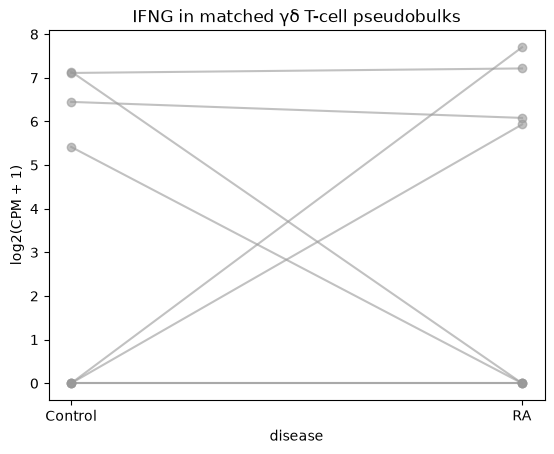

Started: 2026-10-23T14:35:09.099067Z | Wall time: 0.182 s

In [17]:
# Draw one line per matched pair.
axis = paired_values.T.plot(marker="o", legend=False, color="0.6", alpha=0.6)

# Label the two conditions in their plotted order.
axis.set_xticks([0, 1], ["Control", "RA"])

# Label the expression scale used for plotting.
axis.set_ylabel("log2(CPM + 1)")

# Label the panel with the result it shows.
axis.set_title("IFNG in matched γδ T-cell pseudobulks")

# Display the completed figure.
plt.show()

This panel shows donor heterogeneity and paired direction, but it does not estimate dispersion, adjust for batch, fit the matched design, or test a hypothesis. It must not be reported as a differential expression result.

## Pseudo-replicates are not biological replicates

`compare.compute_bulk(..., pseudo_reps=2)` randomly divides cells within a donor. Those partitions can support descriptive stability checks, but they come from the same person and do not increase the biological sample size. This tutorial leaves `pseudo_reps` at its default of one. Using `pseudo_reps` does not compensate for having too few biological donors.

## Common mistakes and limitations
- Treating pseudo-replicates as biological replicates: random partitions of one donor support descriptive stability checks only. Non-independent cells or partitions counted as distinct replicates inflate the degrees of freedom and the false-positive rate of downstream models.
- Feeding normalized values into count-based models: the log2 CPM view on this page is for visualization only. DESeq2, edgeR, and similar frameworks fit negative binomial dispersion and compute their own library-size normalization, so they need the raw integer `bulk` counts.
- Ignoring matched-pair and batch structure: the downstream model must account for the paired design and `batch`, and its effects must be estimable. For this cohort, an intercept plus separate categorical effects for disease, `pair_index_CW`, and `batch` cannot all be estimated separately.
